# Mzazi Care - train and evaluate the hybrid recommender

Notebook version of `train.py`. Run it from the `ml-service` folder. It trains the
`HybridRecommender`, then reports Precision@K, Recall@K, F1, hit rate (the closest thing
to "accuracy" for a recommender), NDCG@K, MAP@K, MRR and catalogue coverage, plus the
cold-start comparison, the alpha/k tuning grid and an encoder comparison.

In [1]:
import json, os, logging
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from db import DataSource
from engine import HybridRecommender, EngineConfig
from encoders import build_encoder, sbert_available

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(message)s")

# ---- settings (the same options train.py takes on the command line)
ENCODER = None        # "sbert" | "tfidf" | None for auto
K = 20
ALPHA = 0.4
TOP_N = 10
TUNE = False          # grid search k and alpha first
COMPARE_ENCODERS = True
FULL = False          # True trains on all interactions (production model)
SAVE = False          # True writes model/hybrid_model.joblib and model_card.json

OUT = Path(os.getenv("MZAZI_MODEL_DIR", Path.cwd().parent / "model"))
OUT.mkdir(parents=True, exist_ok=True)

## 1. Load data

In [2]:
# The train/test split only exists in the seed CSVs, not in MySQL, so evaluation
# reads the CSVs; the production fit (FULL) uses whatever .env points at.
src = DataSource() if FULL else DataSource("csv")
frames = src.load()
providers, categories = frames["providers"], frames["categories"]

train = frames["interactions"] if FULL else src.training_interactions(frames)
test = frames.get("interactions_test", pd.DataFrame())
side = dict(searches=frames.get("search_history"),
            preferences=frames.get("user_preferences"))

print(f"providers {len(providers)}   train {len(train)}   test {len(test)}")
print(f"sentence-transformers installed: {sbert_available()}")

INFO data source: csv
INFO loaded CSVs from C:\Users\kipko\Desktop\LENNY HTML\mzazi-care-system\mzazi-care\database\seed (120 providers, 5012 interactions)


providers 120   train 4367   test 645


c:\Users\kipko\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


sentence-transformers installed: True


## 2. Metric helpers

`engine.evaluate` already gives precision, recall, F1 and hit rate. The helpers below add the ranking metrics (NDCG, MAP, MRR) and coverage by calling `recommend` for every test user.

In [3]:
def cold_items(train, provider_ids, threshold=12):
    pop = train.groupby("provider_id").size().to_dict()
    return {p for p in provider_ids if pop.get(p, 0) < threshold}


def full_metrics(eng, test, top_n=10, alpha=None, only_items=None):
    truth = (test[test.provider_id.isin(eng.p_index)]
             .groupby("user_id").provider_id.apply(set).to_dict())
    P, R, H, NDCG, AP, RR, recommended = [], [], [], [], [], [], set()
    for uid, relevant in truth.items():
        if uid not in eng.u_index:
            continue
        target = relevant & only_items if only_items is not None else relevant
        if not target:
            continue
        res = eng.recommend(user_id=uid, top_n=top_n, alpha=alpha)
        ranked = [r["provider_id"] for r in res["results"]]
        recommended.update(ranked)
        rel = [1 if p in target else 0 for p in ranked]
        hits = sum(rel)
        P.append(hits / top_n)
        R.append(hits / len(target))
        H.append(1.0 if hits else 0.0)
        dcg = sum(r / np.log2(i + 2) for i, r in enumerate(rel))
        idcg = sum(1 / np.log2(i + 2) for i in range(min(len(target), top_n)))
        NDCG.append(dcg / idcg if idcg else 0.0)
        csum, prec = 0, []
        for i, r in enumerate(rel, start=1):
            if r:
                csum += 1
                prec.append(csum / i)
        AP.append(sum(prec) / min(len(target), top_n) if prec else 0.0)
        RR.append(next((1 / i for i, r in enumerate(rel, start=1) if r), 0.0))
    if not P:
        return dict(precision=0, recall=0, f1=0, hit_rate=0, ndcg=0, map=0,
                    mrr=0, coverage=0, users=0)
    p, r = np.mean(P), np.mean(R)
    return dict(precision=p, recall=r, f1=0.0 if p + r == 0 else 2 * p * r / (p + r),
                hit_rate=np.mean(H), ndcg=np.mean(NDCG), map=np.mean(AP),
                mrr=np.mean(RR), coverage=len(recommended) / eng.n_items,
                users=len(P))

## 3. Encoder comparison (optional)

In [4]:
if COMPARE_ENCODERS:
    rows = []
    for choice in ("tfidf", "sbert"):
        if choice == "sbert" and not sbert_available():
            print("skipping sbert - sentence-transformers not installed")
            continue
        cfg = EngineConfig(k=K, alpha=ALPHA, alpha_mode="fixed", encoder=choice)
        e = HybridRecommender(cfg, encoder=build_encoder(choice)).fit(
            providers, train, categories, **side)
        if len(test):
            m = full_metrics(e, test, top_n=TOP_N)
            m_cold = full_metrics(e, test, top_n=TOP_N, alpha=1.0,
                                  only_items=cold_items(train, e.provider_ids))
            rows.append(dict(encoder=e.encoder.name, dim=e.encoder.dim, **m,
                             cold_recall=m_cold["recall"]))
    if rows:
        enc_df = pd.DataFrame(rows)
        enc_df.to_csv(OUT / "encoder_comparison.csv", index=False)
        display(enc_df.round(4))

INFO TF-IDF+SVD fitted: 1964 terms -> 105 dims (99.9% variance)
INFO fitted in 0.7s: 106 providers, 240 users, 4367 interactions, density 5.97%, encoder tfidf-svd:105
INFO No device provided, using cpu
INFO HTTP Request: GET https://huggingface.co/api/agent-harnesses "HTTP/1.1 200 OK"
INFO HTTP Request: GET https://huggingface.co/api/models/sentence-transformers/all-MiniLM-L6-v2 "HTTP/1.1 200 OK"
INFO Loading SentenceTransformer model from sentence-transformers/all-MiniLM-L6-v2.
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 1283.41it/s]
INFO HTTP Request: GET https://huggingface.co/api/models/sentence-transformers/all-MiniLM-L6-v2/tree/main/additional_chat_templates?recursive=false&expand=false "HTTP/1.1 404 Not Found"
INFO HTTP Request: GET https://huggingface.co/api/models/sentence-transformers/all-MiniLM-L6-v2/tree/main?recursive=true&expand=false "HTTP/1.1 200 OK"
INFO HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/1110a243fdf4706

,encoder,dim,precision,recall,f1,hit_rate,ndcg,map,mrr,coverage,users,cold_recall
0,tfidf-svd:105,105,0.0854,0.8542,0.1553,0.8542,0.4896,0.3757,0.3757,1.0,240,1.0000
1,sbert:all-MiniLM-L6-v2,384,0.0829,0.8292,0.1508,0.8292,0.4629,0.3500,0.3500,1.0,240,0.9167


## 4. Train

In [5]:
cfg = EngineConfig(k=K, alpha=ALPHA, alpha_mode="fixed",
                   alpha_source="train.ipynb",
                   encoder=ENCODER or os.getenv("MZAZI_ENCODER", "auto"))
eng = HybridRecommender(cfg).fit(providers, train, categories, **side)
print(f"encoder: {eng.encoder.name}  ({eng.encoder.dim} dims)")
print(f"matrix : {eng.n_users} users x {eng.n_items} providers, density {eng.cfg.density_pct}%")

INFO No device provided, using cpu


INFO HTTP Request: GET https://huggingface.co/api/models/sentence-transformers/all-MiniLM-L6-v2 "HTTP/1.1 200 OK"
INFO Loading SentenceTransformer model from sentence-transformers/all-MiniLM-L6-v2.
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 1391.41it/s]
INFO HTTP Request: GET https://huggingface.co/api/models/sentence-transformers/all-MiniLM-L6-v2/tree/main/additional_chat_templates?recursive=false&expand=false "HTTP/1.1 404 Not Found"
INFO HTTP Request: GET https://huggingface.co/api/models/sentence-transformers/all-MiniLM-L6-v2/tree/main?recursive=true&expand=false "HTTP/1.1 200 OK"
INFO HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/1110a243fdf4706b3f48f1d95db1a4f5529b4d41/2_Normalize/config.json "HTTP/1.1 404 Not Found"
INFO fitted in 7.4s: 106 providers, 240 users, 4367 interactions, density 5.97%, encoder sbert:all-MiniLM-L6-v2


encoder: sbert:all-MiniLM-L6-v2  (384 dims)
matrix : 240 users x 106 providers, density 5.97%


## 5. Tune k and alpha (optional)

In [6]:
if TUNE and len(test):
    grid, best = eng.tune(test, top_n=TOP_N)
    grid.to_csv(OUT / "tuning_results.csv", index=False)
    print(f"tuned: k={eng.cfg.k}  alpha={eng.cfg.alpha}")
    display(grid.sort_values("recall", ascending=False).head(6))

## 6. Evaluation metrics

In [7]:
assert len(test), "no test interactions - cannot evaluate"
cold = cold_items(train, eng.provider_ids)

overall = full_metrics(eng, test, top_n=TOP_N)
content_only = full_metrics(eng, test, top_n=TOP_N, alpha=1.0)
collab_only = full_metrics(eng, test, top_n=TOP_N, alpha=0.0)
cold_content = full_metrics(eng, test, top_n=TOP_N, alpha=1.0, only_items=cold)
cold_collab = full_metrics(eng, test, top_n=TOP_N, alpha=0.0, only_items=cold)

table = pd.DataFrame([
    dict(model="content only (alpha=1)", **content_only),
    dict(model="collaborative only (alpha=0)", **collab_only),
    dict(model=f"hybrid (k={eng.cfg.k}, alpha={eng.cfg.alpha})", **overall),
]).set_index("model")
display(table.round(4))

,precision,recall,f1,hit_rate,ndcg,map,mrr,coverage,users
model,,,,,,,,,
content only (alpha=1),0.0792,0.7917,0.1439,0.7917,0.4693,0.3681,0.3681,1.0000,240
collaborative only (alpha=0),0.0754,0.7542,0.1371,0.7542,0.4101,0.3056,0.3056,0.9906,240
"hybrid (k=20, alpha=0.4)",0.0829,0.8292,0.1508,0.8292,0.4629,0.3500,0.3500,1.0000,240


In [8]:
print(f"Hybrid model, top {TOP_N}, {overall['users']} test users")
print(f"  Accuracy (hit rate) : {overall['hit_rate']:.3f}")
print(f"  Precision           : {overall['precision']:.3f}")
print(f"  Recall              : {overall['recall']:.3f}")
print(f"  F1 score            : {overall['f1']:.3f}")
print(f"  NDCG                : {overall['ndcg']:.3f}")
print(f"  MAP                 : {overall['map']:.3f}")
print(f"  MRR                 : {overall['mrr']:.3f}")
print(f"  Catalogue coverage  : {overall['coverage']:.3f}")
print()
print(f"Cold start - recall@{TOP_N} on the {len(cold)} newest providers")
print(f"  content only        {cold_content['recall']:.3f}")
print(f"  collaborative only  {cold_collab['recall']:.3f}")

Hybrid model, top 10, 240 test users
  Accuracy (hit rate) : 0.829
  Precision           : 0.083
  Recall              : 0.829
  F1 score            : 0.151
  NDCG                : 0.463
  MAP                 : 0.350
  MRR                 : 0.350
  Catalogue coverage  : 1.000

Cold start - recall@10 on the 7 newest providers
  content only        0.917
  collaborative only  0.167


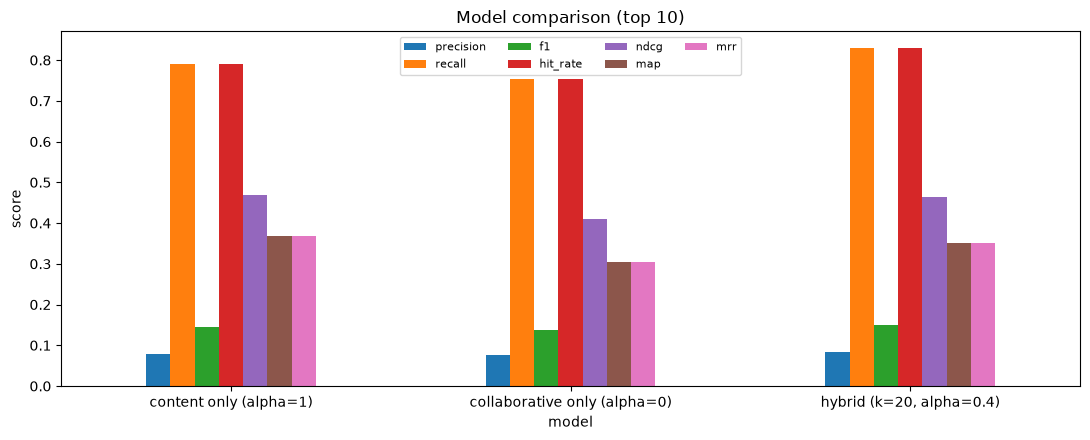

In [9]:
metric_cols = [c for c in table.columns if c not in ("coverage", "users")]
ax = table[metric_cols].plot(kind="bar", figsize=(11, 4.5))
ax.set_ylabel("score"); ax.set_title(f"Model comparison (top {TOP_N})")
plt.xticks(rotation=0); plt.legend(ncol=4, fontsize=8); plt.tight_layout(); plt.show()

,precision,recall,f1,hit_rate,ndcg,map,mrr
K,,,,,,,
1,0.1792,0.1792,0.1792,0.1792,0.1792,0.1792,0.1792
3,0.1361,0.4083,0.2042,0.4083,0.3085,0.2743,0.2743
5,0.1208,0.6042,0.2014,0.6042,0.3888,0.3187,0.3187
10,0.0829,0.8292,0.1508,0.8292,0.4629,0.3500,0.3500
15,0.0581,0.8708,0.1089,0.8708,0.4742,0.3536,0.3536
20,0.0442,0.8833,0.0841,0.8833,0.4772,0.3543,0.3543


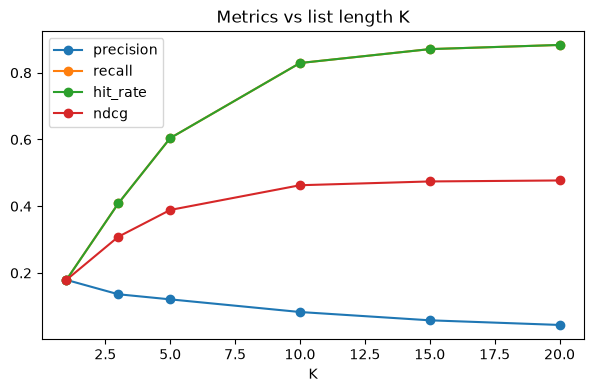

In [10]:
# metrics as the list length grows
ks = [1, 3, 5, 10, 15, 20]
curve = pd.DataFrame([dict(K=k, **full_metrics(eng, test, top_n=k)) for k in ks]).set_index("K")
display(curve[["precision", "recall", "f1", "hit_rate", "ndcg", "map", "mrr"]].round(4))
curve[["precision", "recall", "hit_rate", "ndcg"]].plot(marker="o", figsize=(7, 4),
                                                       title="Metrics vs list length K")
plt.show()

## 7. Save

In [11]:
summary = {"encoder": eng.encoder.name, "config": eng.cfg.to_dict(),
           "metrics": overall, "content_only": content_only,
           "collaborative_only": collab_only, "cold_items": len(cold),
           "cold_recall": dict(content=cold_content["recall"],
                               collaborative=cold_collab["recall"])}
table.to_csv(OUT / "model_comparison.csv")

if SAVE:
    eng.save(str(OUT / "hybrid_model.joblib"))
    (OUT / "model_card.json").write_text(json.dumps(summary, indent=2, default=float))
    print("saved", OUT / "hybrid_model.joblib")
else:
    print("SAVE is False - model not written (set SAVE = True to write it)")

SAVE is False - model not written (set SAVE = True to write it)
